In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

#load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
#totalcharges into numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

#filling the missing total charges with median
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

#removing duplicate rows
df = df.drop_duplicates()

#removing the customer ID
df = df.drop("customerID", axis=1)

#converting target variable
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

#separate features and target
X = df.drop("Churn", axis=1)
y = df["Churn"]

#convert categorical variables into numbers
X = pd.get_dummies(
    X,
    drop_first=True
)

#handling any remaining missing values
X = X.fillna(X.median())

print("Missing values:", X.isnull().sum().sum())
print("Number of original features:", X.shape[1])

#spliting into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#scaling the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Missing values: 0
Number of original features: 30
Training data: (5634, 30)
Testing data: (1409, 30)


PCA components selected: 17


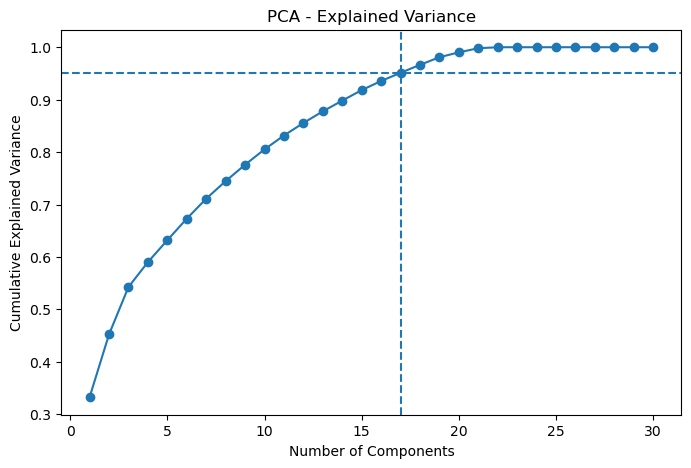


Original features: 30
PCA features: 17
SVD features: 17


In [4]:
# First calculate PCA with all components
pca_full = PCA()

pca_full.fit(X_train_scaled)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

# Find number of components needed for 95% variance
pca_components = np.argmax(
    cumulative_variance >= 0.95
) + 1

print("PCA components selected:", pca_components)

# Plot explained variance
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--"
)

plt.axvline(
    x=pca_components,
    linestyle="--"
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")

plt.show()

#apply pca
pca = PCA(
    n_components=pca_components
)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# use the same number of components for a fair comparison
svd_components = pca_components

svd = TruncatedSVD(
    n_components=svd_components,
    random_state=42
)

X_train_svd = svd.fit_transform(X_train_scaled)
X_test_svd = svd.transform(X_test_scaled)


print("\nOriginal features:", X_train_scaled.shape[1])
print("PCA features:", X_train_pca.shape[1])
print("SVD features:", X_train_svd.shape[1])

In [7]:
#creating five classification models
def create_models():
    
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        
        "Decision Tree": DecisionTreeClassifier(
            random_state=42
        ),
        
        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),
        
        "KNN": KNeighborsClassifier(
            n_neighbors=5
        ),
        
        "SVM": SVC(
            probability=True,
            random_state=42
        )
    }


#store the three feature sets

feature_sets = {
    "Original": (X_train_scaled, X_test_scaled),
    "PCA": (X_train_pca, X_test_pca),
    "SVD": (X_train_svd, X_test_svd)
}


#store results
results = []

#store predictions and probabilities
all_predictions = {}

#run the experiments
for feature_name, (Xtr, Xte) in feature_sets.items():
    
    models = create_models()
    
    for model_name, model in models.items():
        
        start_time = time.time()
        
        #train model
        model.fit(Xtr, y_train)
        
        #predictions
        y_pred = model.predict(Xte)
        
        #probability of churn
        y_prob = model.predict_proba(Xte)[:, 1]
        
        end_time = time.time()
        
        #computational time
        training_time = end_time - start_time
        
        #calculate metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        roc_auc = roc_auc_score(y_test, y_prob)
        
        #number of features
        number_of_features = Xtr.shape[1]
        
        #store results
        results.append([
            feature_name,
            model_name,
            number_of_features,
            accuracy,
            precision,
            recall,
            f1,
            roc_auc,
            training_time
        ])
        
        #store predictions for later plots
        all_predictions[
            (feature_name, model_name)
        ] = {
            "model": model,
            "y_pred": y_pred,
            "y_prob": y_prob
        }

print("All classification experiments completed.")

All classification experiments completed.


In [8]:
#creating results table
results_df = pd.DataFrame(
    results,
    columns=[
        "Feature Set",
        "Model",
        "Number of Features",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Time (seconds)"
    ]
)

#round up numerical values
results_df[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Time (seconds)"
    ]
] = results_df[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Time (seconds)"
    ]
].round(3)

results_df

,Feature Set,Model,Number of Features,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Time (seconds)
0,Original,Logistic Regression,30,0.807,0.658,0.567,0.609,0.842,0.042
1,Original,Decision Tree,30,0.741,0.513,0.492,0.502,0.661,0.026
2,Original,Random Forest,30,0.786,0.622,0.492,0.549,0.825,0.734
3,Original,KNN,30,0.747,0.525,0.500,0.512,0.772,0.233
4,Original,SVM,30,0.793,0.644,0.489,0.556,0.796,7.993
5,PCA,Logistic Regression,17,0.790,0.626,0.519,0.567,0.833,0.017
6,PCA,Decision Tree,17,0.725,0.483,0.500,0.491,0.653,0.176
7,PCA,Random Forest,17,0.773,0.599,0.439,0.506,0.802,2.797
8,PCA,KNN,17,0.746,0.523,0.487,0.504,0.751,0.228
9,PCA,SVM,17,0.797,0.653,0.503,0.568,0.792,7.295


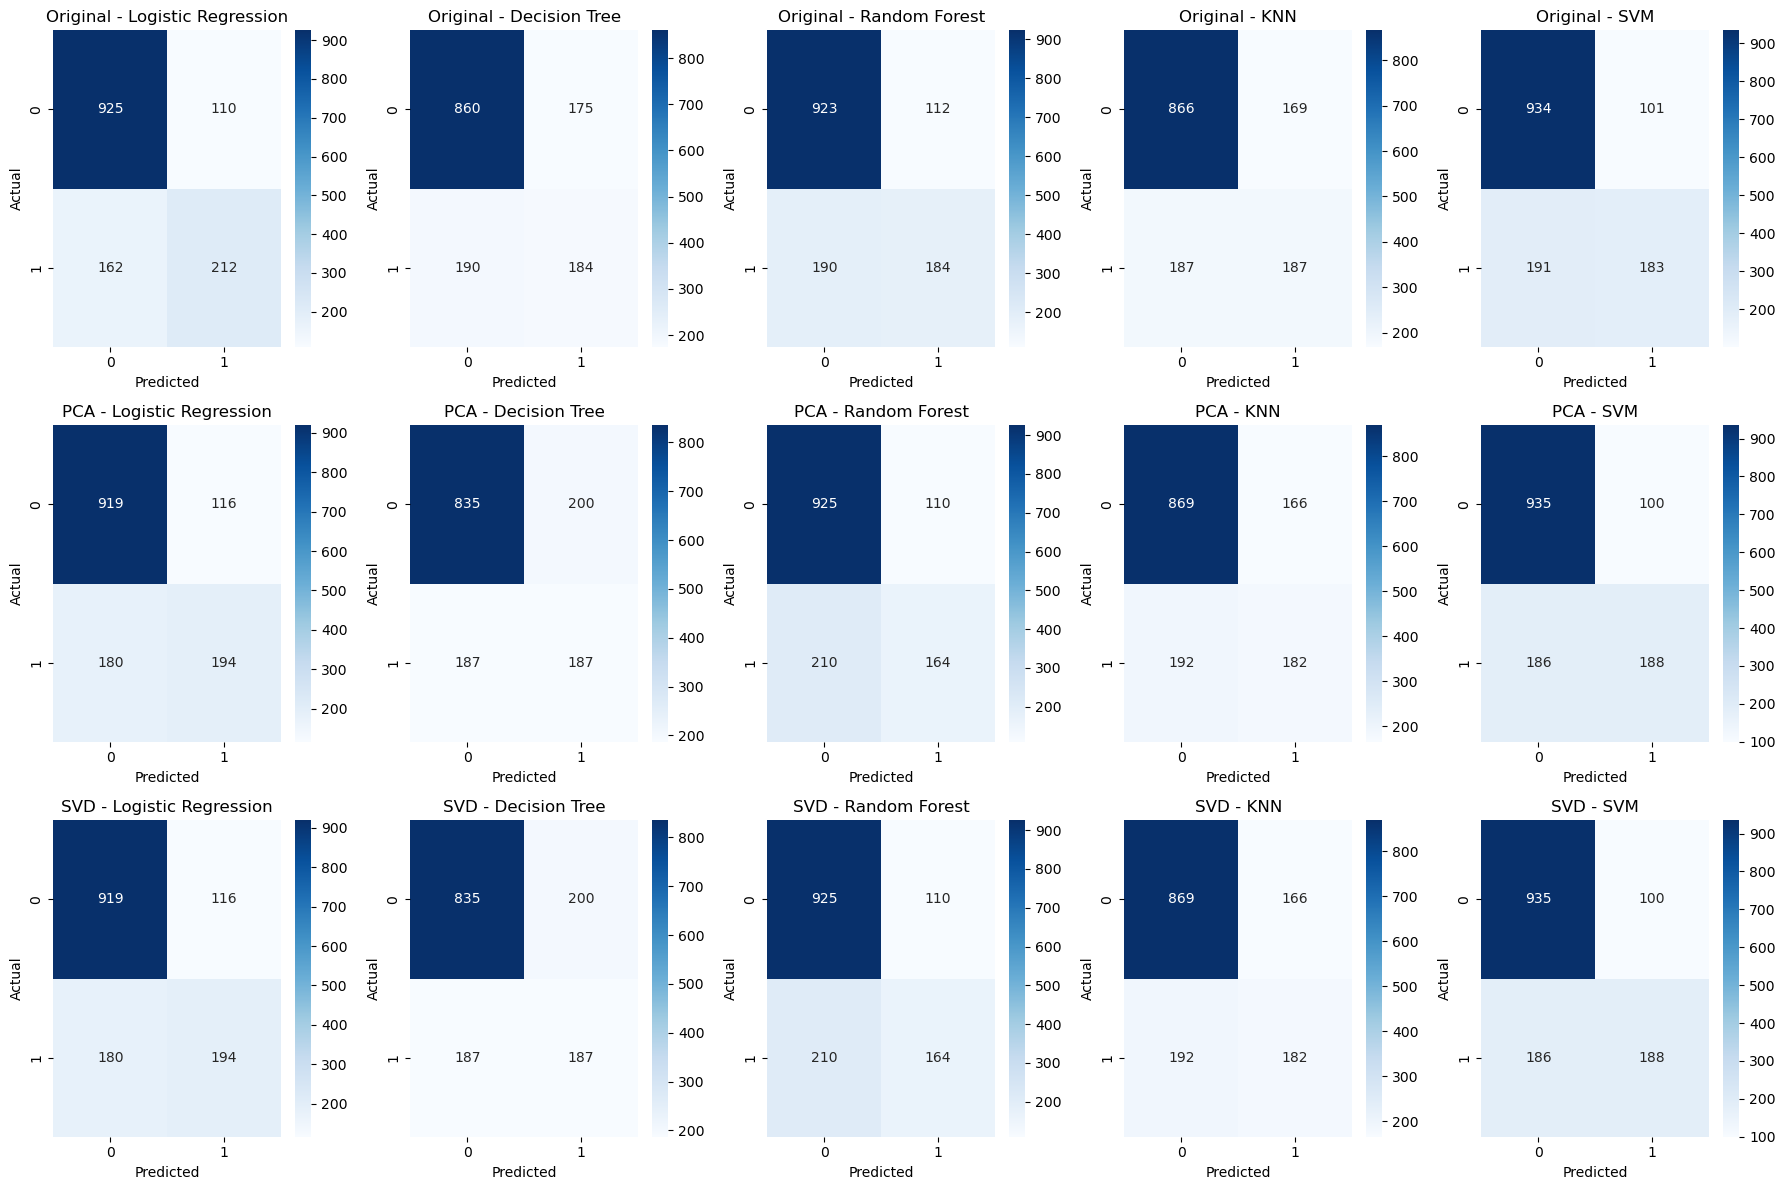

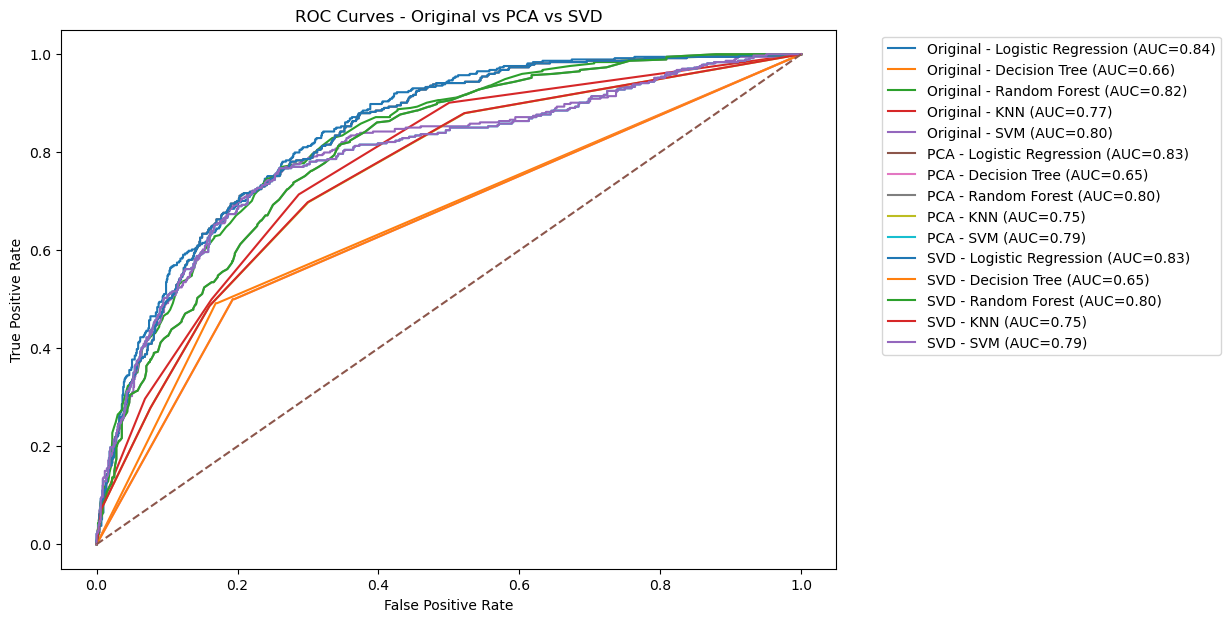

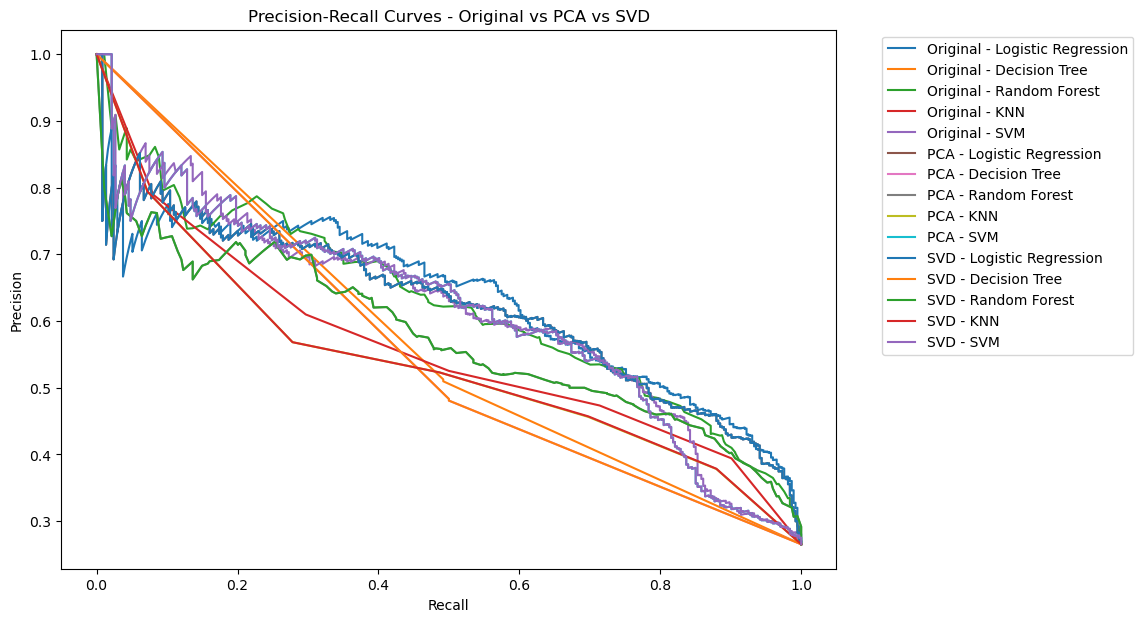

In [9]:
#confusion matrix
fig, axes = plt.subplots(
    3, 5,
    figsize=(18, 12)
)

feature_names = ["Original", "PCA", "SVD"]
model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "KNN",
    "SVM"
]

for i, feature_name in enumerate(feature_names):
    
    for j, model_name in enumerate(model_names):
        
        data = all_predictions[
            (feature_name, model_name)
        ]
        
        cm = confusion_matrix(
            y_test,
            data["y_pred"]
        )
        
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            ax=axes[i, j]
        )
        
        axes[i, j].set_title(
            feature_name + " - " + model_name
        )
        
        axes[i, j].set_xlabel("Predicted")
        axes[i, j].set_ylabel("Actual")

plt.tight_layout()
plt.show()

#roc curves
plt.figure(figsize=(10, 7))

for feature_name in feature_names:
    
    for model_name in model_names:
        
        data = all_predictions[
            (feature_name, model_name)
        ]
        
        fpr, tpr, _ = roc_curve(
            y_test,
            data["y_prob"]
        )
        
        auc = roc_auc_score(
            y_test,
            data["y_prob"]
        )
        
        plt.plot(
            fpr,
            tpr,
            label=f"{feature_name} - {model_name} (AUC={auc:.2f})"
        )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Original vs PCA vs SVD")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.show()

#precision recall Curves
plt.figure(figsize=(10, 7))

for feature_name in feature_names:
    
    for model_name in model_names:
        
        data = all_predictions[
            (feature_name, model_name)
        ]
        
        precision, recall, _ = precision_recall_curve(
            y_test,
            data["y_prob"]
        )
        
        plt.plot(
            recall,
            precision,
            label=f"{feature_name} - {model_name}"
        )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Original vs PCA vs SVD")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.show()

In [10]:
#average performance of each feature set
comparison = results_df.groupby(
    "Feature Set"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Time (seconds)"
    ]
].mean().round(3)

print("Average Performance")
print("-------------------")

comparison

Average Performance
-------------------


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Time (seconds)
Feature Set,,,,,,
Original,0.775,0.592,0.508,0.546,0.779,1.806
PCA,0.766,0.577,0.490,0.527,0.766,2.103
SVD,0.766,0.577,0.490,0.527,0.766,2.092


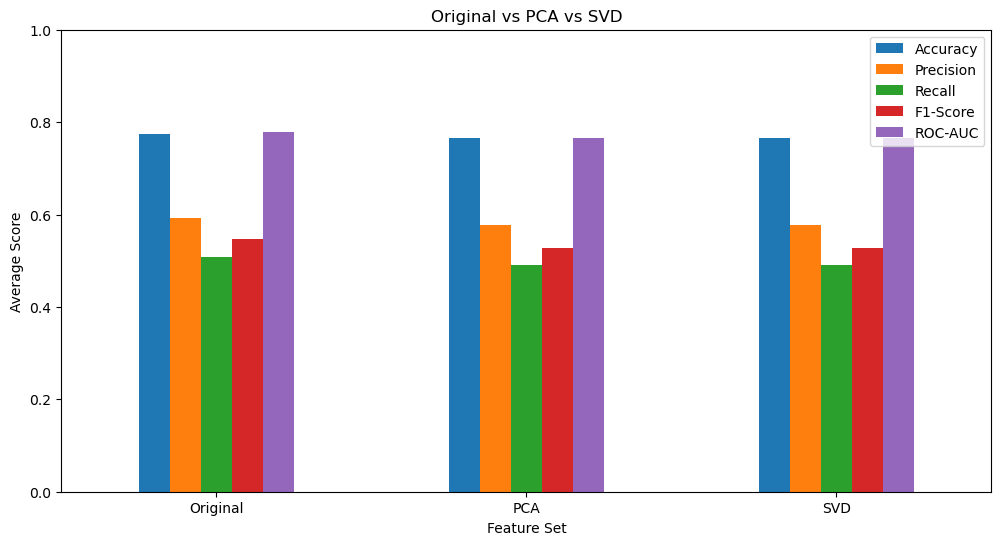

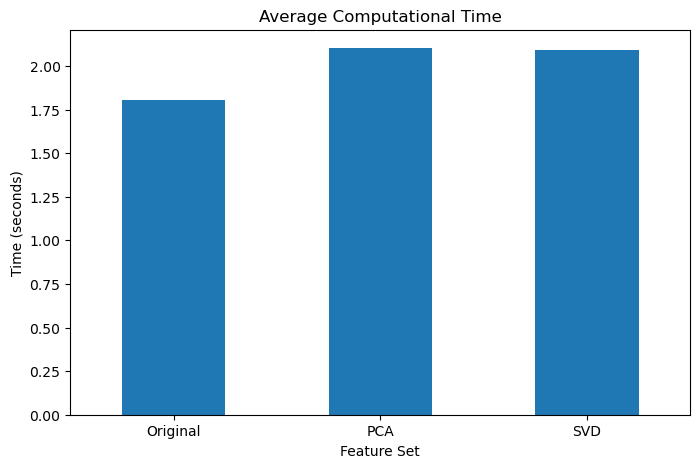

In [11]:
#ploting average model performance
comparison[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Original vs PCA vs SVD")
plt.xlabel("Feature Set")
plt.ylabel("Average Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend()

plt.show()


#comparing computational time
comparison["Time (seconds)"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Computational Time")
plt.xlabel("Feature Set")
plt.ylabel("Time (seconds)")

plt.xticks(rotation=0)

plt.show()

In [12]:
#finding the best feature set based on average ROC and AUC
best_feature_set = comparison[
    "ROC-AUC"
].idxmax()

best_auc = comparison.loc[
    best_feature_set,
    "ROC-AUC"
]

print("FINAL RESULT")
print("==============================")

print(
    "Best feature set based on average ROC-AUC:",
    best_feature_set
)

print(
    "Average ROC-AUC:",
    best_auc
)

print(
    "\nOriginal number of features:",
    X_train_scaled.shape[1]
)

print(
    "PCA number of components:",
    X_train_pca.shape[1]
)

print(
    "SVD number of components:",
    X_train_svd.shape[1]
)


# Compare PCA with Original

original_auc = comparison.loc[
    "Original",
    "ROC-AUC"
]

pca_auc = comparison.loc[
    "PCA",
    "ROC-AUC"
]

svd_auc = comparison.loc[
    "SVD",
    "ROC-AUC"
]

print("\nPERFORMANCE COMPARISON")
print("==============================")

if pca_auc > original_auc:
    print("PCA improved the average ROC-AUC.")
else:
    print("PCA decreased the average ROC-AUC.")

if svd_auc > original_auc:
    print("SVD improved the average ROC-AUC.")
else:
    print("SVD decreased the average ROC-AUC.")

FINAL RESULT
Best feature set based on average ROC-AUC: Original
Average ROC-AUC: 0.779

Original number of features: 30
PCA number of components: 17
SVD number of components: 17

PERFORMANCE COMPARISON
PCA decreased the average ROC-AUC.
SVD decreased the average ROC-AUC.
